# Bias maps: where does neglecting hyperillumination bias $A_B$ and $F$?

The parameter-space part of `01_albedo_bias.ipynb` and `02_redistribution_bias.ipynb`, without a target planet. The noiseless "data" (Asimov dataset) are a `hyperillum` phase curve with Bond albedo $A_{B,\rm true}$ and no heat redistribution. They are fitted with the point-source models, with the baseline free:
1. **$A_B$ only** (`naive`), as in `01_albedo_bias.ipynb`.
2. **$A_B$ and $F$ jointly** (`naive_redist`, Kreidberg & Loeb 2016 heat redistribution), as in `02_redistribution_bias.ipynb`. The truth has $F = 0$, so the fitted $F$ is itself the bias in $F$.

Each section has a bias map over $(a/R_\star, T_{\rm eff})$ (the $(a/R_\star, R_p/R_\star)$ map is commented out in the same cell), a per-planet decision for the planets of the paper (`PAPER_PLANETS`, which are also the labelled planets on every map), and one planet retrieved with several instruments, as the fitted $A_B$ and as the occultation depth of the fit. 1.5 and 2.7 add the fit of all three detectors (NIRSpec NRS1 + NRS2 and MIRI/LRS) at once, for the multi-band consistency of the spurious $F$; 2.3 also shows the $(A_B, F)$ $\chi^2$ landscape behind the joint fit of that planet on `instrument`.

The maps are computed at a **reference geometry** set in the setup below, not at any particular planet: the inclination `incl_ref` (a central transit by default, so every cell occults), the fixed $R_p/R_\star$ of the $T_{\rm eff}$ map (`rp_rs_ref`) and the fixed $T_{\rm eff}$ of the $R_p/R_\star$ map (`T_eff_ref`). The period drops out of the bias. The maps do not depend on the noise or the number of orbits; the per-planet decisions do.
With a central transit, the maps **overstate** the bias of planets with a large impact parameter (see the end of 1.2). The per-planet decisions fit every planet at its own geometry and are not affected.

`instrument` is one band (`JWST_BANDS`) or the joint NIRSpec fit `JWST_NIRSpec.G395H_joint`: the two G395H arrays fitted together with one shared $A_B$ (and $F$), a baseline per array and the $\chi^2$ summed over both (a *detector set*, `simple_bias_analysis.is_detector_set`). The maps, the per-planet tables and the false-positive map then refer to that joint fit: the maps take one common placeholder noise, the tables carry one noise level per array (`sigma_1min:<label>` columns, `noise_cols` lists them). The per-instrument sections (1.3, 1.4, 1.5, 2.3, 2.4, 2.7) fit their own instrument lists and do not depend on `instrument`.

Set `target` to a `PlanetParams` to draw one planet as the green star on every map; by default no planet is highlighted.

In [1]:
import numpy as np
import os
import contextlib, io
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle the SPIDERMAN workers between parallel blocks
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from HItargets_utils import *

# Exoplanet Archive (to populate bias map)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'inputs', 'exoplanet_archive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Reference geometry of the maps. Each map sweeps a/Rs and one more parameter; everything else is held at these values.
incl_ref  = 90.     # [deg] central transit, so every map cell occults
rp_rs_ref = DEFAULT_MAP_RP_RS   # Rp/Rs held fixed on the (a/Rs, T_eff) map: the median of the paper planets (baseline, HItargets_utils.py)
T_eff_ref = 4000.   # [K] T_eff held fixed on the (a/Rs, Rp/Rs) map
ref = reference_planet(rp_rs=rp_rs_ref, T_eff=T_eff_ref, incl=incl_ref)   # a/Rs is swept; period and stellar radius are placeholders the bias does not depend on

u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # transit and irradiance limb darkening (baseline settings, HItargets_utils.py)

In [3]:
# Albedos (baseline settings, HItargets_utils.py)
A_B_true = DEFAULT_A_B                    # Bond albedo: sets the temperature map
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B

In [4]:
# Filter and observation
instrument = "MIRI/LRS"   # a band ("JWST_NIRSpec.G395H_NRS1", "MIRI/LRS", "MIRI/F1280W", ...) or the joint NIRSpec fit "JWST_NIRSpec.G395H_joint" (both G395H arrays: one shared A_B / F, a baseline per array)
n_bins = DEFAULT_N_BINS   # number of bins in one orbit
n_orbits = DEFAULT_N_ORBITS   # number of orbits observed; enters only the per-planet decisions (the maps are noise-independent)


# sigma_1min is a placeholder for the maps: the bias is the chi^2 minimum, which does not depend on the noise scale. Only the convergence tolerance of the
# joint fit (absolute in chi^2) does, so keep it realistic. The per-planet decisions replace it with each planet's own PandExo noise.
# The band-less FittingConfig holds everything but the band; instrument_cfg adds the band of `instrument`, or for a joint fit one config per array (a detector set, the same placeholder noise on each).
cfg = instrument_cfg(FittingConfig(planet=ref, A_=A_model,
                                   sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins,
                                   reflected=True, u_bol=u_bol, u=u), instrument)

set_plot_style()
geom = rf"$A_B$ = {A_B_true:.2f}, $i$ = {incl_ref:g}°"   # for the figure titles


In [5]:
# Map grids (shared by both sections). With a target, map_grid widens the box so that the target lies on its own map.
a_rs_grid = map_grid(1.2, 4.0, 15)
T_eff_grid = map_grid(3000., 7000., 9)
rp_rs_grid = map_grid(0.01, 0.025, 10)
# Panels of the *.1 bias maps: absolute |Delta A_B| and / or relative |Delta A_B| / A_B. (False, True) shows the relative map alone.
show_absolute, show_relative = False, True

kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)     # n_layers is left to the per-model default of pcurve_params (40 hyperillum, 60 naive / naive_redist)

# Sample of the per-planet tables (1.2, 2.2, 2.6): the planets of the paper. Every per-planet plot and map takes its own planet list (planets=PAPER_PLANETS in the calls below).
# PandExo noise per planet, from the PandExo cache where possible (HItargets_utils.PANDEXO_CACHE): only a configuration not run before takes seconds. {name: ppm/min}; for a joint fit {name: {detector: ppm/min}}.
sigma_paper = rms_1min_pandexo_sample(PAPER_PLANETS, instrument)

## 1. Bias in $A_B$ (A_B-only fit, `naive`)

### 1.1 In which regimes does hyperillumination matter? Bias map over (a/Rs, T_eff)

Theoretically the period P should be varied with (a/R★) for a fixed ρ★ = 3π(a/R★)³/(GP²). This is not necessary and does not change the result, since the period is degenerate in the bias analysis.

non-railed cells: 135 of 135;  Delta A_B in [-0.926, -0.009] = [-462.8, -4.5] % of A_B
fitted A_B < 0 in 25 of 135 cells;  railed: 0


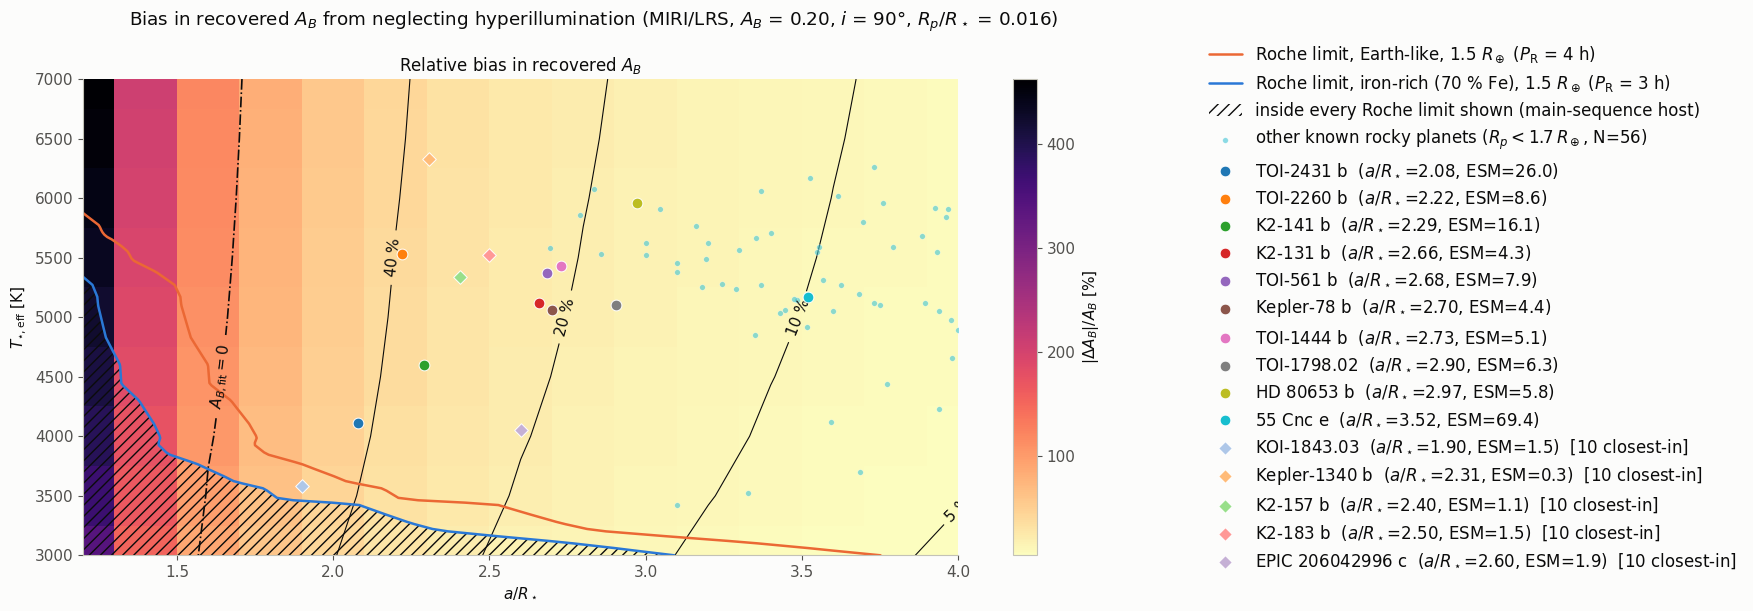

In [6]:
# The bias in recovered A_B is a pure model-degeneracy quantity, so this map is independent of the noise level sigma. The cells are independent -> run in parallel.
# return_chi2: the chi^2 map of the fits is kept for the false-positive map of 2.5, which reuses it instead of refitting.
bias_map_T, chi2_map_T = bias_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", return_chi2=True, **kw)
fig, axs = plot_bias_maps(a_rs_grid, T_eff_grid, bias_map_T, A_B_true, AGG, "st_teff", r"$T_{\star,\rm eff}$ [K]",
               rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, planets=PAPER_PLANETS, show_absolute=show_absolute, show_relative=show_relative,   # panel switches from the setup
               title=rf"Bias in recovered $A_B$ from neglecting hyperillumination ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g})")
plt.show()

# bias_map = bias_map_grid(cfg, A_B_true, a_rs_grid, rp_rs_grid, "rp_rs", **kw)
# plot_bias_maps(a_rs_grid, rp_rs_grid, bias_map, A_B_true, AGG, "pl_ratror", r"$R_p/R_\star$",
#                rp_rs_of=lambda y: y, incl=incl_ref, planets=PAPER_PLANETS, show_absolute=show_absolute, show_relative=show_relative,   # panel switches from the setup
#                title=rf"Bias in recovered $A_B$ from neglecting hyperillumination ({instrument}, {geom}, $T_{{\rm eff}}$ = {T_eff_ref:g} K)")

The fits are not bounded by the physical floor: $A_B$ is fitted in `A_B_FIT_BOUNDS` = $(-2, 1)$, so the bias stays defined where the point-source model needs more absorbed energy than the star delivers to a point. The dash-dot contour marks the fitted $A_B = 0$, i.e. $\Delta A_B = -A_B$ (100 % on the relative map); towards small $a/R_\star$ the fit lies below it, where a retrieval with the physical prior $A_B \in [0, 1]$ would rail at 0. The lines under the map give the range of $\Delta A_B$ and count the cells with $A_{B,\rm fit} < 0$. Grey cells would mark railed fits (a fit on a bound of its range), which this fit range does not produce. The panels are chosen in the setup (`show_absolute`, `show_relative`): the absolute bias $|\Delta A_B|$, the relative bias $|\Delta A_B|/A_B$, or both; the same switches apply to the joint-fit map of 2.1. The coloured curves are the Roche limits of an Earth-like and an iron-rich (70 % Fe) rocky planet of 1.5 $R_\oplus$ around a main-sequence host (`HItargets_utils.ROCHE_CASES`, `simple_bias_analysis.roche_periods`; theory and a check against the known planets in `06_roche_limit.ipynb` §1). Left of the iron-rich line (hatched) no rocky planet of that size survives, so those cells describe no planet under these assumptions. The lines are main-sequence references: a planet's own distance from its limit is $(P/P_{\rm R})^{2/3}$, independent of the host. They appear on every $(a/R_\star, T_{\rm eff})$ map (`roche=False` hides them).

What to look for: the sign of $\Delta A_B$ (an underestimate is the expected hyperillumination signature), how fast $|\Delta A_B|$ falls with $a/R_\star$ (where the 0.05 and 0.02 contours lie), and how the contours move with $T_{\rm eff}$. In the configurations run (MIRI/LRS and NIRSpec G395H), the bias is an underestimate everywhere, growing with $T_{\rm eff}$ at fixed $a/R_\star$.

### 1.2 Per-planet decision: does hyperillumination matter for the closest-in rocky planets?

The planets of the paper (`PAPER_PLANETS`), each re-fitted with its **own** geometry and its **own** PandExo noise for this instrument, at the same assumed $A_B$.
The bias is noise-independent (it is a pure model-degeneracy quantity), so only the Fisher $\sigma_{A_B}$ moves with the noise and
$\sigma_{1\rm min, crit} = \sigma_{1\rm min}\,|\Delta A_B|/\sigma_{A_B}$ is an identity, not an extrapolation: the per-minute precision at which the bias would be a $1\sigma$ effect.
A planet needs hyperillumination exactly where the delivered $\sigma_{1\rm min}$ is at or below the required $\sigma_{1\rm min, crit}$.

A planet whose Fisher $\sigma_{A_B}$ is at or above the flat-prior std $(hi - lo)/\sqrt{12}$ of the physical range `A_B_BOUNDS` (0.289 for $A_B \in [0, 1]$, dashed line; the prior of the dynesty fits, not the wider fit range) is marked *unconstrained*: there $|\Delta A_B|/\sigma_{A_B}$ is a ratio to a meaningless number, so neither "needs hyperillumination" nor "naive OK" applies. A Gaussian as wide as the prior std carries no information relative to the box ($H = \ln[(hi-lo)/(\sigma\sqrt{2\pi e})] \approx -0.2$ nats; its truncated posterior is the prior, and dynesty returns exactly the prior std there).

For a joint fit of several detectors the table has one delivered noise per array (`sigma_1min:<label>`) and one critical noise per array (`sigma_1min_crit:<label>`: that array's noise times the common $|\Delta A_B|/\sigma_{A_B}$ of the joint fit); the scalar `sigma_1min` / `sigma_1min_crit` columns are then NaN, and `noise_cols` picks the ones to print.


In [7]:
tab_AB = planet_bias_table(cfg, A_B_true, PAPER_PLANETS, sigma_paper, AGG=AGG, **kw)   # cfg supplies filter / stellar grid / albedo model / n_bins / n_orbits; geometry and sigma_1min are per planet; AGG supplies the ESM / Rp rows

# Three-way verdict (bias_verdict): bias >= 1 sigma needs hyperillumination; below it naive is OK only where sigma_A_B is below the flat-prior std of the physical range A_B_BOUNDS, otherwise A_B is simply unconstrained.
for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED, VERDICT_NO_NOISE):
    sel = tab_AB[tab_AB.verdict == v]
    print(f"{len(sel)} of {len(tab_AB)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_AB[["name", "a_rs", "esm", "bias", "sigma", "bias_sigma", *noise_cols(tab_AB), "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))   # noise_cols: sigma_1min and sigma_1min_crit, per detector for a joint fit


1 of 10 needs hyperillum: TOI-2431 b
8 of 10 naive OK: TOI-2260 b, K2-141 b, K2-131 b, TOI-561 b, TOI-1444 b, TOI-1798.02, HD 80653 b, 55 Cnc e
1 of 10 unconstrained: Kepler-78 b
0 of 10 no noise level: -
       name  a_rs   esm     bias   sigma  bias_sigma  sigma_1min  sigma_1min_crit          verdict
 TOI-2431 b  2.08 25.96 -0.05978 0.05308       1.126       62.93            70.86 needs hyperillum
 TOI-2260 b  2.22 8.632 -0.02822  0.1328      0.2126       114.2            24.28         naive OK
   K2-141 b 2.292 16.12 -0.06373 0.08532       0.747       99.24            74.13         naive OK
   K2-131 b  2.66 4.323 -0.04181  0.2053      0.2037       280.3            57.11         naive OK
  TOI-561 b 2.683 7.927 -0.04276  0.1197      0.3571       99.41             35.5         naive OK
Kepler-78 b   2.7 4.415 -0.02025  0.2946     0.06873       202.2            13.89    unconstrained
 TOI-1444 b  2.73 5.114 -0.03632  0.1927      0.1885       145.8            27.48         naive OK
TOI

The verdicts and the table above are the result: a planet needs hyperillumination where `bias_sigma` $\ge 1$, i.e. where the delivered $\sigma_{1\rm min}$ is at or below $\sigma_{1\rm min, crit}$. Planets whose PandExo noise is too high to measure $A_B$ at all come out *unconstrained*.

**The maps overstate the bias of inclined planets.** The per-planet table fits every planet at its own geometry, while the maps assume the reference inclination `incl_ref`. The cell below reads each planet's bias off the $(a/R_\star, T_{\rm eff})$ map of 1.1 at its position and compares it with its own-geometry fit (`map_vs_planet_bias`; `map_excess` > 0: the map overstates).
Planets with a large impact parameter $b = (a/R_\star)\cos i$ come out too large on the map, while for $b \approx 0$ the two agree closely. Re-fitting a planet at its own $a/R_\star$, $R_p/R_\star$ and $T_{\rm eff}$ but $i = 90°$ reproduces the map value (checked for the planets of the paper with MIRI/LRS, $A_B = 0.2$, $u_{\rm bol} = 0.5$, map $R_p/R_\star = 0.016$: the $i = 90°$ refit and the map value agree to better than 0.002), so the difference is almost entirely the inclination; the map's fixed $R_p/R_\star$ and the interpolation between its cells hardly contribute. Reading planets off the $(a/R_\star, R_p/R_\star)$ map instead adds the fixed `T_eff_ref` as a second error, largest for the hottest stars.
For scale, lowering the reference inclination to 74° shrinks the whole map (median $|\Delta A_B|$ $-40\,\%$ in the cells that still occult; $(a/R_\star, T_{\rm eff})$ map, MIRI/LRS, $A_B = 0.2$, $u_{\rm bol} = 0.5$, $R_p/R_\star = 0.016$) and removes the occultation beyond $a/R_\star \approx 3.7$.
The verdicts above are not affected, because they use the own-geometry fit.

In [8]:
# Each planet's bias read off the (a/Rs, T_eff) map of 1.1 at its position (bias_map) against its own-geometry fit of 1.2 (bias_own); map_excess > 0: the map overstates
print(map_vs_planet_bias(tab_AB, hi_planets_by_name(PAPER_PLANETS), a_rs_grid, T_eff_grid, bias_map_T).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

       name      b  bias_own  bias_map  map_excess
 TOI-2260 b 0.7702  -0.02822  -0.07739     0.04918
 TOI-2431 b 0.5733  -0.05978  -0.08609     0.02631
Kepler-78 b 0.6897  -0.02025  -0.04209     0.02184
 HD 80653 b 0.4292  -0.02724   -0.0345    0.007264
 TOI-1444 b 0.3799  -0.03632   -0.0421    0.005781
TOI-1798.02 0.3188  -0.03085  -0.03449    0.003637
   55 Cnc e  0.393  -0.01738  -0.01983    0.002451
   K2-131 b 0.2318  -0.04181  -0.04401    0.002197
   K2-141 b 0.1479  -0.06373  -0.06587    0.002138
  TOI-561 b 0.1404  -0.04276  -0.04394    0.001175


### 1.3 One planet, several instruments: retrieved $A_B$
After Ramirez et al. 2026 (arXiv:2610.22338), Fig. 4. For one planet (`retrieval_planet`), the hyperillumination truth with Bond albedo `A_B_inj` is fitted with the $A_B$-only model on each instrument of `retrieval_instruments`. Each point is the fitted $A_B$, with the Fisher $1\sigma$ (dark) and $2\sigma$ (light) error bars; the dashed line is the injected value. Each instrument uses the planet's own geometry and noise level: PandExo where it has a mode, otherwise the planet's entry in `CUSTOM_SIGMA_1MIN` (`HItargets_utils.py`). Instruments with neither are still fitted, since the fitted $A_B$ does not depend on the noise, and drawn as a half-filled marker without error bars. An entry given as a tuple of detectors, here the two NIRSpec/G395H arrays, is one **joint fit** of those detectors: one shared $A_B$, a separate baseline offset per detector, and the $\chi^2$ summed over both arrays. It gets its own position in the plot (NaN as `sigma_1min` in the table; the per-detector noise levels are in `tab.attrs["sigma_1min"]`). A hollow marker means the fit is *unconstrained* (Fisher $\sigma$ at or above the flat-prior std), so its error bar does not measure anything. A fitted $A_B$ can lie below 0 (the fits are not railed at the physical floor); the axis then extends below the dash-dot $A_B = 0$ line, into the shaded range outside the physical prior.

What to look for: whether the injected value lies inside the $1\sigma$ / $2\sigma$ bars. The offset of each point from the dashed line is that instrument's bias. It changes with the band, because the share of reflected and thermal light and the hyperillumination signal depend on wavelength. The bar width scales with each instrument's noise level. The joint NRS1 + NRS2 point should land between the two single-array points with a narrower bar, since the two arrays constrain the same $A_B$.

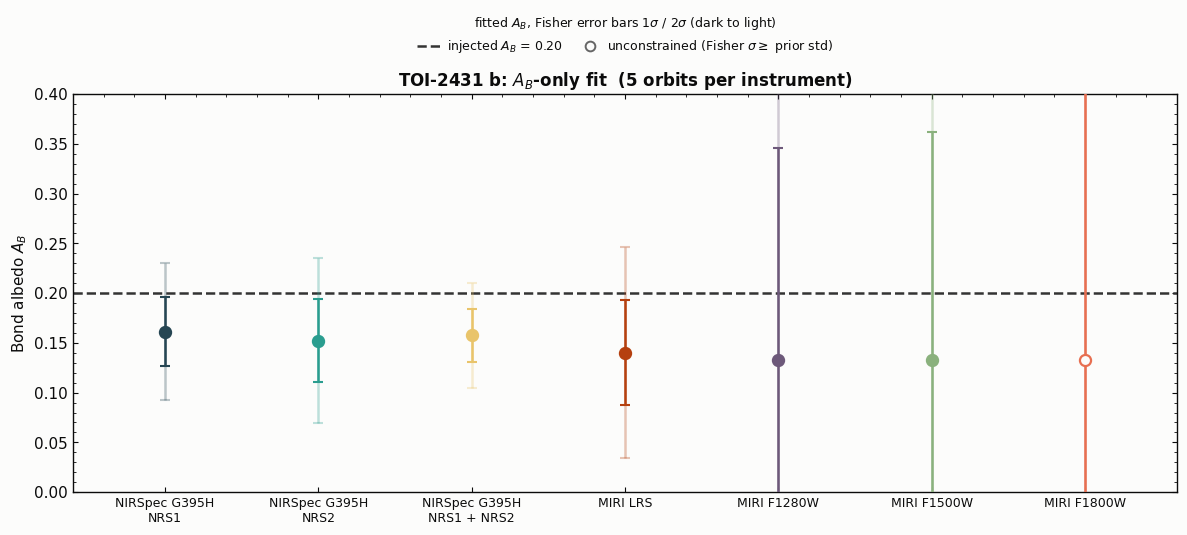

                                     instrument  sigma_1min  A_B_fit  bias_A_B  sigma_A_B  bias_sigma          verdict
                        JWST_NIRSpec.G395H_NRS1       39.13   0.1613  -0.03873    0.03455       1.121 needs hyperillum
                        JWST_NIRSpec.G395H_NRS2       49.41   0.1522  -0.04777    0.04151       1.151 needs hyperillum
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2           -   0.1575  -0.04245    0.02655       1.599 needs hyperillum
                                       MIRI/LRS       62.93   0.1402  -0.05978    0.05308       1.126 needs hyperillum
                                    MIRI/F1280W       247.2    0.133  -0.06701     0.2132      0.3143         naive OK
                                    MIRI/F1500W         264   0.1326  -0.06744     0.2291      0.2944         naive OK
                                    MIRI/F1800W       396.2   0.1325  -0.06748     0.3459      0.1951    unconstrained


In [9]:
# One planet on several instruments: fitted A_B +- Fisher sigma per instrument, for a hyperillumination truth injected at A_B_inj.
retrieval_planet = hi_planets_by_name("TOI-2431 b")
retrieval_instruments = JWST_RETRIEVALS   # sorted by wavelength (the plots of 1.3, 1.4, 2.3, 2.4 and 2.6 keep this order); the tuple in it is one joint fit of the two NIRSpec arrays
A_B_inj = A_B_true   # injected Bond albedo; n_orbits and the band albedo model come from cfg

tab_inst_AB = instrument_retrievals(cfg, retrieval_planet, retrieval_instruments, A_B_inj, **kw)
sigma_inst = tab_inst_AB.attrs["sigma_1min"]   # {detector: ppm/min}; 2.3 reuses these noise levels
fig, ax = plot_instrument_retrievals(tab_inst_AB, title=f"{retrieval_planet.name}: $A_B$-only fit  ({n_orbits} orbits per instrument)")
plt.show()
print(tab_inst_AB.drop(columns=["F_fit", "sigma_F", "chi2"]).to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))   # chi2: kept for 2.6

### 1.4 One planet, several instruments: occultation depth of the fit
The fits of 1.3 seen through the observable instead of the parameter: for each instrument, the occultation depth $\delta$ of the fitted $A_B$-only model next to the depth of the hyperillumination truth. No refit: the fitted parameters of 1.3 are reused, so run 1.3 first.

Both depths are evaluated exactly at mid-occultation (`model_depth`): the thermal part with `occultation_depth()` on the fitted SPIDERMAN model (unblocked minus blocked flux at the occultation time), the reflected part as the planet's reflected flux at full phase. This is not the phase-curve height just before ingress, which on these short-period planets sits well below the depth because the phase still changes over the long occultation. The depth uses more SPIDERMAN layers than the fit (`DEPTH_N_LAYERS`), since the naive depth converges only slowly with `n_layers`.

Each point is the fitted depth $\delta_{\rm fit}$; the true depth differs between bands, so each instrument has its own dashed segment at $\delta_{\rm true}$. The error bars are the depth's Fisher $1\sigma$ / $2\sigma$, propagated from the fit's parameter covariance ($\sigma_\delta^2 = \nabla\delta^{\mathsf T} C\, \nabla\delta$). A hollow marker means the fit is unconstrained in $A_B$, as in 1.3. The joint NRS1 + NRS2 fit of 1.3 is left out here: the depth is a per-band quantity, so a two-array fit has no single depth.

What to look for: whether the fitted depth stays within its error bar of the truth while $A_B$ (1.3) is biased. If it does, the eclipse alone gives no sign that the model is misspecified.

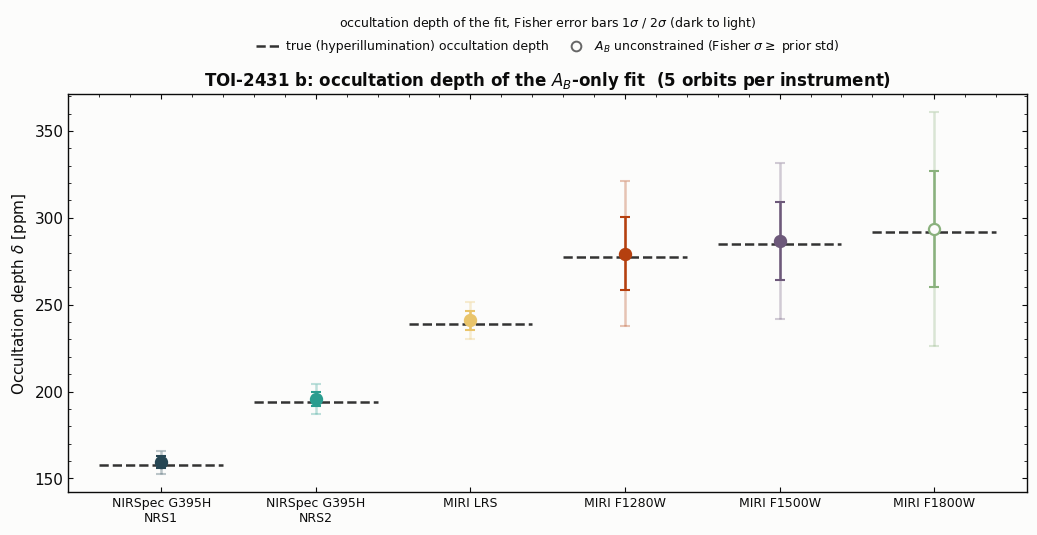

             instrument  A_B_fit  depth_true  depth_fit  bias_depth  sigma_depth  depth_bias_sigma  bias_sigma          verdict
JWST_NIRSpec.G395H_NRS1   0.1613         158      159.3       1.275        3.374             0.378       1.121 needs hyperillum
JWST_NIRSpec.G395H_NRS2   0.1522         194      195.7        1.71        4.234            0.4039       1.151 needs hyperillum
               MIRI/LRS   0.1402         239        241       2.014         5.36            0.3758       1.126 needs hyperillum
            MIRI/F1280W    0.133       277.6      279.4       1.823        20.99           0.08687      0.3143         naive OK
            MIRI/F1500W   0.1326         285      286.6       1.673         22.4           0.07471      0.2944         naive OK
            MIRI/F1800W   0.1325       292.1      293.5       1.492         33.6           0.04439      0.1951    unconstrained


In [10]:
# Occultation depth of each A_B-only fit of 1.3 (no refit), exact at mid-occultation, against the true hyperillumination depth on the same instrument.
tab_depth_AB = instrument_depths(cfg, retrieval_planet, tab_inst_AB, **kw)   # same cfg / planet / kw as the fits of 1.3
fig, ax = plot_instrument_retrievals(tab_depth_AB, quantity="depth", title=f"{retrieval_planet.name}: occultation depth of the $A_B$-only fit  ({n_orbits} orbits per instrument)")
plt.show()
depth_cols = ["instrument", "A_B_fit", "F_fit", "depth_true", "depth_fit", "bias_depth", "sigma_depth", "depth_bias_sigma", "bias_sigma", "verdict"]   # bias_sigma / verdict: those of A_B, for comparison
print(tab_depth_AB[[c for c in depth_cols if c != "F_fit"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

### 1.5 All three detectors in one fit: NIRSpec + MIRI/LRS
The detector sets of `instrument_retrievals` are not limited to the two NIRSpec arrays. Here NRS1, NRS2 and MIRI/LRS are fitted as **one** fit with a shared $A_B$ and a baseline per detector, next to its two parts (MIRI/LRS alone, the joint NIRSpec fit), for the planets of `multi_planets`. This is the noiseless counterpart of a retrieval that combines a NIRSpec and a MIRI phase curve of the same planet. The cell prints tables only.

What to look for: the combined fit has the smallest $\sigma_{A_B}$, so its bias is the most significant. $\chi^2_{\min}$ of the combined fit against the sum of its parts (`excess`) measures how well one $A_B$ serves all bands: the $A_B$-only bias is nearly band-independent, so the excess should be small, and the expected evidence $\chi^2_{\min}/2$ of the combined data nearly the sum of the parts.

In [11]:
# NRS1 + NRS2 + MIRI/LRS as ONE fit (shared A_B, a baseline per detector), next to its parts
multi_planets = ("TOI-2431 b", "K2-141 b")
multi_instruments = ["MIRI/LRS", tuple(JWST_BANDS[:2]), (*JWST_BANDS[:2], "MIRI/LRS")]
MULTI_LABEL = dict(zip([instrument_key(ins) for ins in multi_instruments], ("MIRI/LRS", "joint NIRSpec", "NIRSpec + LRS")))

tab_multi_AB = {nm: instrument_retrievals(cfg, hi_planets_by_name(nm), multi_instruments, A_B_true, **kw) for nm in multi_planets}
for nm, t in tab_multi_AB.items():
    t = t.assign(mode=t["instrument"].map(MULTI_LABEL), lnB_mean=0.5 * t["chi2"])
    print(nm)
    print(t[["mode", "A_B_fit", "bias_A_B", "sigma_A_B", "bias_sigma", "chi2", "lnB_mean", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    c = t.set_index("mode")["chi2"]
    print(f"   chi2_min: combined {c['NIRSpec + LRS']:.2f}, sum of the parts {c['MIRI/LRS'] + c['joint NIRSpec']:.2f}  ->  excess {c['NIRSpec + LRS'] - c['MIRI/LRS'] - c['joint NIRSpec']:.2f}\n")

TOI-2431 b
         mode  A_B_fit  bias_A_B  sigma_A_B  bias_sigma  chi2  lnB_mean          verdict
     MIRI/LRS   0.1402  -0.05978    0.05308       1.126 12.64     6.318 needs hyperillum
joint NIRSpec   0.1575  -0.04245    0.02655       1.599 11.58     5.792 needs hyperillum
NIRSpec + LRS    0.154  -0.04598    0.02374       1.937 24.31     12.15 needs hyperillum
   chi2_min: combined 24.31, sum of the parts 24.22  ->  excess 0.09

K2-141 b
         mode  A_B_fit  bias_A_B  sigma_A_B  bias_sigma  chi2  lnB_mean          verdict
     MIRI/LRS   0.1363  -0.06373    0.08532       0.747 4.114     2.057         naive OK
joint NIRSpec   0.1576  -0.04241    0.03724       1.139 5.157     2.578 needs hyperillum
NIRSpec + LRS   0.1541  -0.04589    0.03412       1.345 9.324     4.662 needs hyperillum
   chi2_min: combined 9.32, sum of the parts 9.27  ->  excess 0.05



## 2. Joint bias in $A_B$ and $F$ (`naive_redist`)

The same maps for the joint fit of $A_B$, $F$ and the baseline. The truth has $F = 0$, so the fitted $F$ is the bias in $F$: heat redistribution that the data do not contain. $F$ is bounded to $[0, 0.5]$, and $F = 0$ is a valid fit.
With an inclination below 90°, cells whose impact parameter $b = (a/R_\star)\cos i$ reaches $1 + R_p/R_\star$ have no occultation and are greyed out: without the eclipse nothing anchors the flux level, and $A_B$ and $F$ become degenerate. The dashed lines then bound the grazing zone. With a central transit every cell occults, so neither appears.

### 2.1 In which regimes does hyperillumination matter? Bias maps over (a/Rs, T_eff)

occulting, non-railed cells: 135 of 135;  Delta A_B in [-0.956, -0.031] = [-478.2, -15.3] % of A_B,  F in [0.0012, 0.0196]
fitted A_B < 0 in 44 of 135 cells;  railed: 0,  without occultation: 0


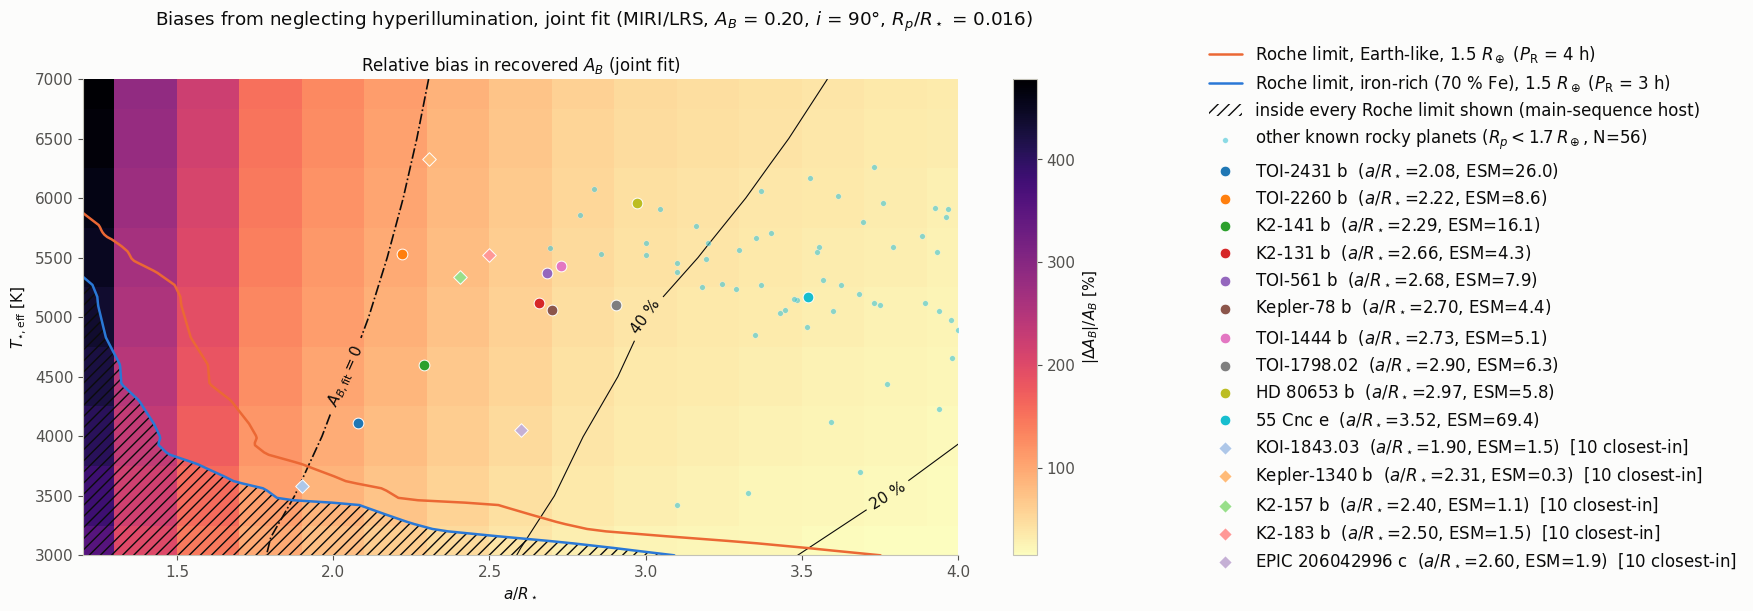

In [12]:
# The biases are pure model-degeneracy quantities, so these maps are independent of the noise level sigma. The cells are independent -> run in parallel.
# return_chi2: the chi^2 map of the fits is kept for the false-positive map of 2.5, which reuses it instead of refitting.
bias_map_JT, F_map_JT, chi2_map_JT = bias_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", redist=True, return_chi2=True, **kw)
fig, axs = plot_bias_maps(a_rs_grid, T_eff_grid, bias_map_JT, A_B_true, AGG, "st_teff", r"$T_{\star,\rm eff}$ [K]",
               rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, F_map=F_map_JT, planets=PAPER_PLANETS,
               show_absolute=show_absolute, show_relative=show_relative, show_F=False,   # panel switches from the setup; show_F=True adds the fitted-F panel
               title=rf"Biases from neglecting hyperillumination, joint fit ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g})")
plt.show()

# bias_map, F_map = bias_map_grid(cfg, A_B_true, a_rs_grid, rp_rs_grid, "rp_rs", redist=True, **kw)
# plot_bias_maps(a_rs_grid, rp_rs_grid, bias_map, A_B_true, AGG, "pl_ratror", r"$R_p/R_\star$",
#                rp_rs_of=lambda y: y, incl=incl_ref, F_map=F_map, planets=PAPER_PLANETS,
#                show_absolute=show_absolute, show_relative=show_relative, show_F=False,   # panel switches from the setup; show_F=True adds the fitted-F panel
#                title=rf"Biases from neglecting hyperillumination, joint fit ({instrument}, {geom}, $T_{{\rm eff}}$ = {T_eff_ref:g} K)")

The line under the map gives the range of $\Delta A_B$ and of the fitted $F$; `show_F=True` adds the $F$ map.

What to look for: how much larger the joint bias is than the $A_B$-only bias of 1.1, and whether the fitted $F$ is non-zero everywhere. Freeing $F$ lets the fit trade albedo for a spurious nightside: the fit lowers $A_B$ and adds a small $F$. In the configurations run, $F > 0$ in every cell, and the joint map has the same smooth shape as 1.1 with every contour moved to larger $a/R_\star$: the joint bias is larger, by a factor that grows away from the star (compare the printed ranges).
The joint fit profiles out $A_B$ and scans $F$ (`fit_redist`). A local optimizer started at $F = 0$ gets stuck on that bound, because the nightside switches on extremely flatly with $F$ ($T_{\rm night} \propto F^{1/4}$).

### 2.2 Per-planet decision: does the biased $A_B$ (and the spurious $F$) matter for the closest-in rocky planets?

The planets of the paper (`PAPER_PLANETS`), each re-fitted with its **own** geometry and its **own** PandExo noise for this instrument, at the same assumed $A_B$.
The truth has $F = 0$, so the fitted $F$ **is** the bias: a non-zero value is heat redistribution that the data do not contain, i.e. hyperillumination masquerading as an atmosphere.
The decision columns (`bias`, `sigma`, `bias_sigma`, `sigma_1min_crit`) refer to $A_B$ by default; pass `quantity="F"` to `planet_bias_table` to put them on the spurious $F$ instead.
$\sigma_{1\rm min, crit} = \sigma_{1\rm min}\,|{\rm bias}|/\sigma$ is then the precision at which that bias would be reported as a $1\sigma$ effect -- and the planets where the delivered precision already beats it are the ones where a naive fit would report an albedo (or a redistribution) that is not there.

A planet whose Fisher $\sigma$ is at or above the flat-prior std $(hi - lo)/\sqrt{12}$ of the physical range (0.289 for $A_B \in [0, 1]$, dashed line; 0.144 for $F \in [0, 0.5]$; `A_B_BOUNDS`, `F_BOUNDS`, the priors of the dynesty fits) is marked *unconstrained*: there ${\rm bias}/\sigma$ is a ratio to a meaningless number, so neither "needs hyperillumination" nor "naive OK" applies. A Gaussian as wide as the prior std carries no information relative to the box ($H = \ln[(hi-lo)/(\sigma\sqrt{2\pi e})] \approx -0.2$ nats; its truncated posterior is the prior, and dynesty returns exactly the prior std there).


In [13]:
# redist=True -> the joint (A_B, F) fit; quantity defaults to "A_B", so bias / sigma / bias_sigma / sigma_1min_crit all refer to the albedo bias (pass quantity="F" for the spurious redistribution instead).
tab_redist = planet_bias_table(cfg, A_B_true, PAPER_PLANETS, sigma_paper, redist=True, AGG=AGG, **kw)
title_tail = f"({instrument}, $A_B$ = {A_B_true:.2f}, {n_orbits} orbits, {n_bins} bins)"

# Three-way verdict (bias_verdict): bias >= 1 sigma needs hyperillumination; below it naive is OK only where sigma_A_B is below the flat-prior std of the physical range A_B_BOUNDS, otherwise A_B is simply unconstrained.
for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED, VERDICT_NO_NOISE):
    sel = tab_redist[tab_redist.verdict == v]
    print(f"{len(sel)} of {len(tab_redist)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_redist[["name", "a_rs", "esm", "bias_A_B", "sigma_A_B", "F_fit", "sigma_F", "bias_sigma", *noise_cols(tab_redist), "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))


3 of 10 needs hyperillum: TOI-2431 b, K2-141 b, 55 Cnc e
6 of 10 naive OK: TOI-2260 b, K2-131 b, TOI-561 b, TOI-1444 b, TOI-1798.02, HD 80653 b
1 of 10 unconstrained: Kepler-78 b
0 of 10 no noise level: -
       name  a_rs   esm  bias_A_B  sigma_A_B    F_fit  sigma_F  bias_sigma  sigma_1min  sigma_1min_crit          verdict
 TOI-2431 b  2.08 25.96   -0.1691    0.07049 0.005813 0.002416       2.399       62.93              151 needs hyperillum
 TOI-2260 b  2.22 8.632     -0.16     0.1964 0.003684 0.004415      0.8145       114.2            93.05         naive OK
   K2-141 b 2.292 16.12   -0.1561     0.1119 0.003967 0.003064       1.396       99.24            138.5 needs hyperillum
   K2-131 b  2.66 4.323   -0.1092     0.2748 0.002726  0.00736      0.3972       280.3            111.3         naive OK
  TOI-561 b 2.683 7.927   -0.1127     0.1605 0.002524 0.003883      0.7022       99.41             69.8         naive OK
Kepler-78 b   2.7 4.415    -0.109     0.4643 0.003272  0.01333      0

The verdicts and the table above are the result. Compare with 1.2: the joint $A_B$ bias is larger than the $A_B$-only bias for every planet, and the fit attributes part of the misfit to a spurious $F$. That can push a planet from *naive OK* to *needs hyperillumination*, although the Fisher $\sigma_{A_B}$ grows as well because of the $A_B$–$F$ degeneracy. The *unconstrained* planets stay unconstrained.
As in 1.2, the cell below reads each planet's joint bias off the $(a/R_\star, T_{\rm eff})$ map of 2.1 (`map_vs_planet_bias`). For $b \approx 0$ the map and the own-geometry fit agree closely, and the largest excesses again belong to planets with a large impact parameter. Unlike the $A_B$-only bias, however, the joint bias does not always grow towards $i = 90°$, so the map can also understate it (negative `map_excess`), and the interpolation between the map cells adds an error of its own (refits at $i = 90°$ with the planet's own and with the map's $R_p/R_\star$, for the planets of the paper; MIRI/LRS, $A_B = 0.2$, $u_{\rm bol} = 0.5$, map $R_p/R_\star = 0.016$: the inclination accounts for most of the excess of TOI-2260 b, TOI-2431 b and TOI-1444 b; Kepler-78 b and HD 80653 b have a smaller joint bias at $i = 90°$ than at their own inclination; the difference for 55 Cnc e is mostly interpolation; the fixed $R_p/R_\star$ contributes at most 0.002).

In [14]:
# The same for the joint fit: each planet's joint A_B bias read off the map of 2.1 against its own-geometry fit of 2.2
print(map_vs_planet_bias(tab_redist, hi_planets_by_name(PAPER_PLANETS), a_rs_grid, T_eff_grid, bias_map_JT).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

       name      b  bias_own  bias_map  map_excess
 TOI-2260 b 0.7702     -0.16   -0.1918     0.03185
 TOI-2431 b 0.5733   -0.1691   -0.1821     0.01291
 TOI-1444 b 0.3799   -0.1013   -0.1094    0.008047
   K2-131 b 0.2318   -0.1092   -0.1134    0.004258
   K2-141 b 0.1479   -0.1561   -0.1587    0.002604
  TOI-561 b 0.1404   -0.1127   -0.1144    0.001634
TOI-1798.02 0.3188  -0.08715  -0.08842    0.001267
Kepler-78 b 0.6897    -0.109   -0.1077   -0.001318
 HD 80653 b 0.4292   -0.0976  -0.09275   -0.004854
   55 Cnc e  0.393  -0.07504  -0.06521   -0.009827


The same per-planet result in the figure style of 2.3: the fitted $A_B$ itself (not the bias) with its Fisher $1\sigma$ / $2\sigma$ bars, the joint fit (squares) next to the $A_B$-only fit of 1.2 (circles), one position per planet. The dashed line is the assumed $A_B$. Every planet of the list is shown; a fit that leaves $A_B$ *unconstrained* gets a hollow marker, and its bars are only the prior width. Fits below the dash-dot $A_B = 0$ line lie outside the physical range.

What to look for: the table of 2.2 read as a figure -- whether the assumed $A_B$ lies inside each planet's bars, and how far freeing $F$ pulls the squares below the circles.

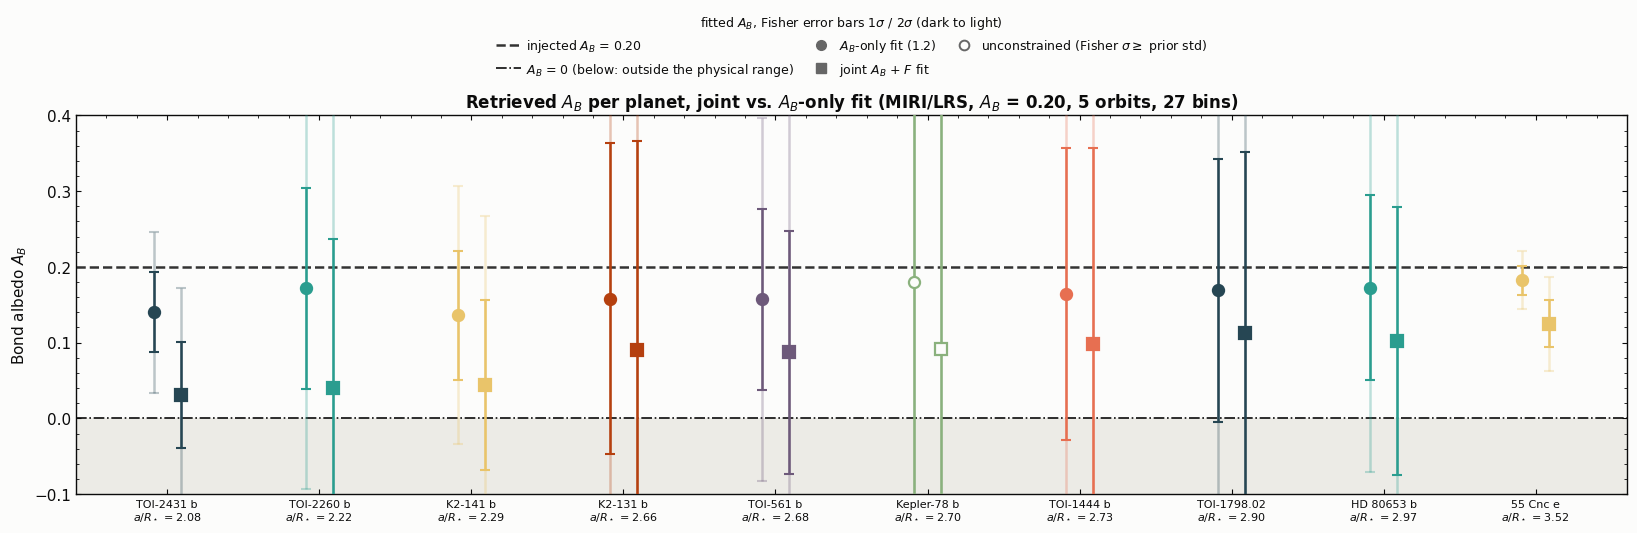

In [15]:
# 2.2 as a retrieval plot (one position per planet, on this instrument): the joint fit of this section next to the A_B-only fit of 1.2, for every planet of the list.
fig, ax = plot_planet_retrievals({"$A_B$-only fit (1.2)": tab_AB, "joint $A_B$ + $F$ fit": tab_redist}, planets=PAPER_PLANETS,
                                 title=f"Retrieved $A_B$ per planet, joint vs. $A_B$-only fit {title_tail}")
plt.show()

### 2.3 One planet, several instruments: retrieved $A_B$ with the joint fit
The same as 1.3 for the joint $A_B$ + $F$ fit (squares), next to the $A_B$-only fit of 1.3 (circles), as the paper's figure sets two fits side by side. It reuses the planet, instruments, injected $A_B$ and noise levels of 1.3, so run 1.3 first. The table also lists the spurious $F$ and its Fisher $\sigma$ per instrument. The joint NRS1 + NRS2 fit shares $A_B$ and $F$ between the arrays, with a baseline per array.

What to look for: how far freeing $F$ moves each instrument's point away from the dashed line, and whether the joint bars still reach the injected value.

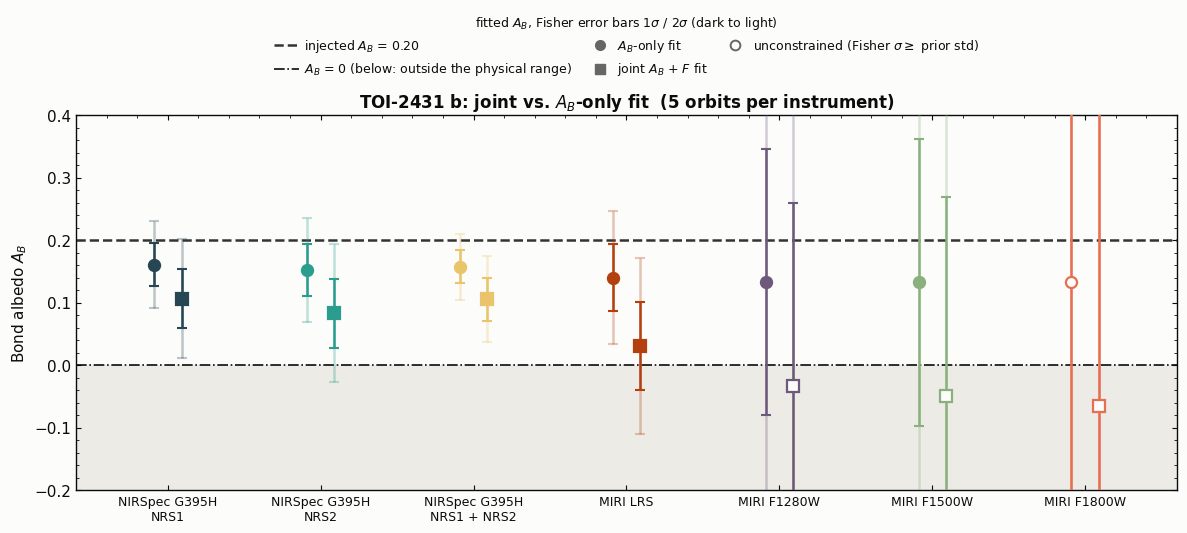

                                     instrument  sigma_1min  A_B_fit  bias_A_B  sigma_A_B    F_fit  sigma_F  bias_sigma          verdict
                        JWST_NIRSpec.G395H_NRS1       39.13   0.1068  -0.09318    0.04774  0.01943  0.00893       1.952 needs hyperillum
                        JWST_NIRSpec.G395H_NRS2       49.41  0.08325   -0.1167    0.05504  0.01279 0.005432       2.121 needs hyperillum
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2           -   0.1057   -0.0943    0.03461  0.01402 0.004748       2.724 needs hyperillum
                                       MIRI/LRS       62.93  0.03086   -0.1691    0.07049 0.005813 0.002416       2.399 needs hyperillum
                                    MIRI/F1280W       247.2 -0.03383   -0.2338     0.2932 0.002514 0.003438      0.7976    unconstrained
                                    MIRI/F1500W         264 -0.04941   -0.2494     0.3183 0.002005 0.002866      0.7837    unconstrained
                                    MIRI/

In [16]:
# The joint (A_B, F) fit per instrument, set next to the A_B-only fit of 1.3 (same planet, instruments, injected A_B and noise levels).
tab_inst_J = instrument_retrievals(cfg, retrieval_planet, retrieval_instruments, A_B_inj, redist=True, sigma_1min=sigma_inst, **kw)
fig, ax = plot_instrument_retrievals({"$A_B$-only fit": tab_inst_AB, "joint $A_B$ + $F$ fit": tab_inst_J},
                                     title=f"{retrieval_planet.name}: joint vs. $A_B$-only fit  ({n_orbits} orbits per instrument)")
plt.show()
print(tab_inst_J.drop(columns=["chi2"]).to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))   # chi2: kept for 2.6

#### The $\chi^2$ landscape behind the joint fit
The $(A_B, F)$ landscape of the joint fit for `retrieval_planet` on `instrument` (from `02_redistribution_bias.ipynb`): the planet's own geometry and noise, i.e. the row of 1.3 and 2.3 for this instrument (for a joint fit of several detectors the $\chi^2$ is summed over them, each with its own baseline). It uses the same noiseless residual as `fit_redist` (baseline free) on an $(A_B, F)$ grid, relative to the joint best fit. The contours mark $\Delta\chi^2 = 2.30$ and $6.18$ above the minimum: models inside them could not be told apart from the best fit at 68 % and 95 % with this observation.

What to look for: the valley from the $A_B$-only fit at $F = 0$ to the joint minimum at lower $A_B$ and $F > 0$ is the $A_B$–$F$ degeneracy that widens the joint bars of 2.3, and whether the truth lies inside the 68 % or 95 % contour says how significant the joint bias is on this instrument.


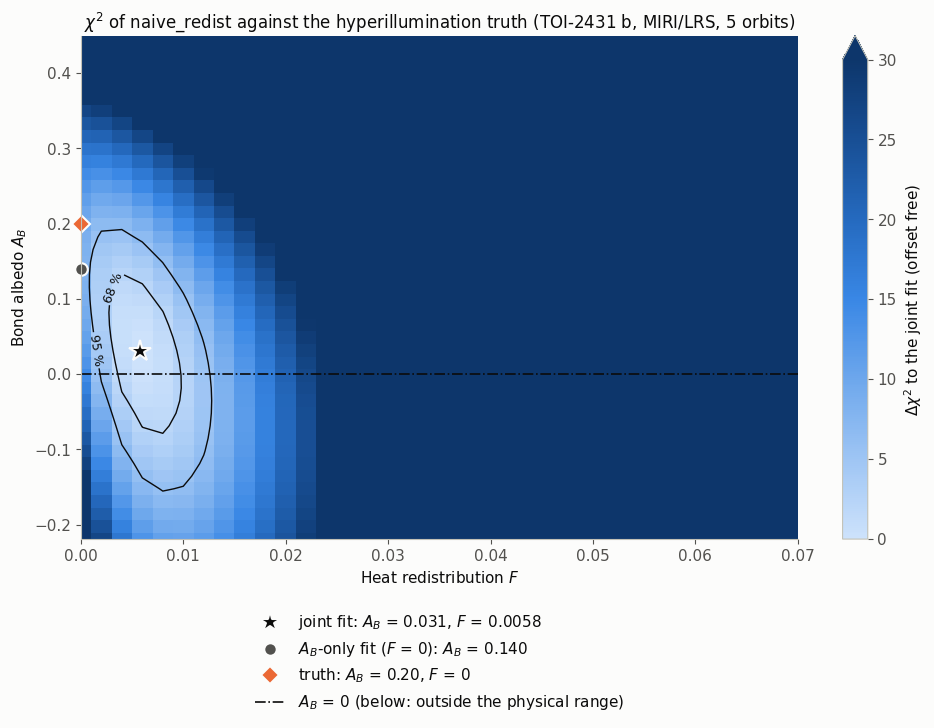

68 % region on the grid: A_B in [-0.07, 0.13],  F <= 0.008


In [17]:
# chi^2 landscape of the joint fit for retrieval_planet on `instrument`: the planet's geometry, the band(s) and the noise of its row in 1.3 / 2.3 (a joint fit sums chi^2 over its detectors), relative to the joint best fit.
cfg_land = retrieval_cfg(cfg, retrieval_planet, instrument, sigma_1min=sigma_inst)   # the cfg (or detector set) of the 1.3 / 2.3 row of this instrument
truth_land = truth_curves(cfg_land, A_B_inj, **kw)
fit_land = fit_truth(cfg_land, A_B_inj, models=("naive", "naive_redist"), **kw)   # the A_B-only and the joint fit (the same tolerances as the tables)
A_fit, A_fit2, F_fit2 = fit_land["naive"]["A_B_fit"], fit_land["naive_redist"]["A_B_fit"], fit_land["naive_redist"]["F_fit"]

F_MAX = 0.07   # plotted F range: widen it if the 95 % contour does not close inside the plot
# 0.25 below both fits (which can lie below A_B = 0, A_B_FIT_BOUNDS) up to 0.25 past the truth and both fits, so the grid survives config changes
AB_grid = np.linspace(max(A_B_FIT_BOUNDS[0], min(A_fit, A_fit2) - 0.25), min(A_B_FIT_BOUNDS[1], max(A_B_inj, A_fit, A_fit2) + 0.25), 41)
F_grid = np.linspace(0., F_MAX, 36)
d_chi2 = chi2_landscape(cfg_land, truth_land, AB_grid, F_grid, **kw) - fit_chi2(cfg_land, truth_land, "naive_redist", A_fit2, F=F_fit2, **kw)   # relative to the joint best fit
# d_chi2 is referenced to the joint fit, not to the grid minimum, and plot_chi2_landscape has vmin=0 -- an underconverged fit would be invisible. print(d_chi2.min()) must be >= 0.

fig, ax = plot_chi2_landscape(F_grid, AB_grid, d_chi2, F_MAX)
ax.plot(F_fit2, A_fit2, "*", ms=16, color=INK, mec="#fcfcfb", mew=1.5, label=f"joint fit: $A_B$ = {A_fit2:.3f}, $F$ = {F_fit2:.4f}")
ax.plot(0., A_fit, "o", ms=9, color=C_NAIVE, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"$A_B$-only fit ($F$ = 0): $A_B$ = {A_fit:.3f}")
ax.plot(0., A_B_inj, "D", ms=9, color=C_HI, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"truth: $A_B$ = {A_B_inj:.2f}, $F$ = 0")
if AB_grid[0] < 0.: ax.axhline(0., label="$A_B$ = 0 (below: outside the physical range)", **FIT_ZERO)
ax.set_title(f"$\\chi^2$ of naive_redist against the hyperillumination truth ({retrieval_planet.name}, {instrument}, {n_orbits} orbits)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

if not (d_chi2 < 2.30).any():
    raise ValueError("68 % region is not on the grid: widen AB_grid or F_MAX")
(A_lo, A_hi), F_hi = chi2_region(d_chi2, AB_grid, F_grid)
print(f"68 % region on the grid: A_B in [{A_lo:.2f}, {A_hi:.2f}],  F <= {F_hi:.3f}")


### 2.4 One planet, several instruments: occultation depth of the joint fit
The same as 1.4 for the joint $A_B$ + $F$ fits of 2.3 (squares), next to the $A_B$-only fits (circles). It reuses the tables of 1.3, 1.4 and 2.3, so run those first. The depth's Fisher $\sigma$ now includes the $A_B$–$F$ correlation of the joint covariance. As in 1.4, the joint NRS1 + NRS2 fits are left out.

What to look for: whether freeing $F$ moves the fitted depth away from the truth, or whether the joint fit trades a larger $A_B$ bias for the same depth. Compare the depth offsets in units of their $\sigma$ (`depth_bias_sigma`) with the $A_B$ ones (`bias_sigma`).

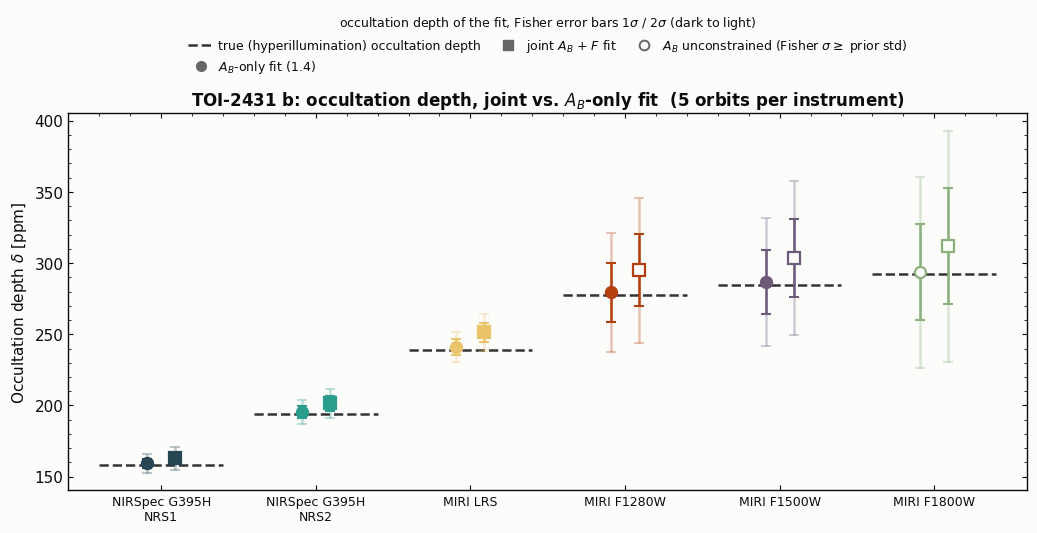

             instrument  A_B_fit    F_fit  depth_true  depth_fit  bias_depth  sigma_depth  depth_bias_sigma  bias_sigma          verdict
JWST_NIRSpec.G395H_NRS1   0.1068  0.01943         158      162.8       4.776        4.032             1.185       1.952 needs hyperillum
JWST_NIRSpec.G395H_NRS2  0.08325  0.01279         194      201.5       7.511        5.094             1.475       2.121 needs hyperillum
               MIRI/LRS  0.03086 0.005813         239      251.4       12.35         6.48             1.906       2.399 needs hyperillum
            MIRI/F1280W -0.03383 0.002514       277.6        295       17.42        25.42            0.6851      0.7976    unconstrained
            MIRI/F1500W -0.04941 0.002005         285      303.5       18.53        27.14            0.6829      0.7837    unconstrained
            MIRI/F1800W -0.06517 0.001575       292.1      311.7       19.63        40.73             0.482      0.5459    unconstrained


In [18]:
# Occultation depth of each joint fit of 2.3 (no refit), set next to the A_B-only depths of 1.4.
tab_depth_J = instrument_depths(cfg, retrieval_planet, tab_inst_J, **kw)
fig, ax = plot_instrument_retrievals({"$A_B$-only fit (1.4)": tab_depth_AB, "joint $A_B$ + $F$ fit": tab_depth_J}, quantity="depth",
                                     title=f"{retrieval_planet.name}: occultation depth, joint vs. $A_B$-only fit  ({n_orbits} orbits per instrument)")
plt.show()
print(tab_depth_J[depth_cols].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

### 2.5 Where does the spurious $F$ become a false-positive atmosphere? Critical noise map over (a/Rs, T_eff)
The joint fit returns $F > 0$ everywhere on the 2.1 map although the truth has no heat redistribution. An observer who finds $F > 0$ *significantly* would report heat transport, i.e. an atmosphere. How significant the spurious $F$ is, is measured by the likelihood ratio of the two fits of this notebook,
$$\Delta\chi^2_F = \chi^2(A_B\text{-only fit}) - \chi^2(\text{joint } A_B + F \text{ fit}),$$
both at their best fit with a free baseline, on the noiseless truth. $\sqrt{\Delta\chi^2_F}$ is then the median expected one-sided significance of "$F > 0$" (Asimov data set, Cowan et al. 2011). It is exact for the nonlinear $T \propto F^{1/4}$ response and for the boundary at $F = 0$, which is why it is used instead of $F/\sigma_F$: the Fisher $\sigma_F$ is the local slope at $F_{\rm fit}$, but the model responds $\propto F^{1.5}$ near zero, so extrapolating to $F = 0$ overstates the significance, and the boundary is ignored.

No refit: the two fits per cell are those of the maps of 1.1 and 2.1, so the map is built from their $\chi^2$ maps (`fits=`). Run 1.1 and 2.1 first.

$\Delta\chi^2_F$ scales exactly as $n_{\rm orbits}/\sigma_{1\,\rm min}^2$ (the fits themselves do not depend on the noise scale), so the map does not show $\Delta\chi^2_F$ at the placeholder noise but the **critical noise** $\sigma_{1\,\rm min,\,crit} = \sigma_{1\,\rm min}\sqrt{\Delta\chi^2_F}/z$: the per-minute precision at which the spurious $F$ is a $z\sigma$ detection with the notebook's `n_orbits`. A planet observed with better precision than that gets the false positive. The map holds $R_p/R_\star$ and $i$ at the reference values; the signal is $\propto (R_p/R_\star)^2$, so $\sigma_{\rm crit} \propto (R_p/R_\star)^2$, and a planet's own noise level should be compared with the map only after that rescaling (or fitted at its own geometry, as in 2.2).

What to look for: the critical noise rises towards small $a/R_\star$ and hot stars, where the hyperillumination signal that the fit mistakes for redistribution is largest. Compare the contour values with the PandExo noise levels of 1.2/2.2 (`sigma_paper`, tens to a few hundred ppm/min) to see which part of the map is within reach of a single JWST programme. The printed line also gives the significance range at the placeholder noise.

occulting, non-railed cells: 135 of 135;  sigma_1min,crit (2 sigma, 5 orbits) in [4.7, 493.1] ppm/min;  sqrt(dchi2_F) at sigma_1min = 100 ppm/min in [0.09, 9.86] sigma
railed: 0,  without occultation: 0


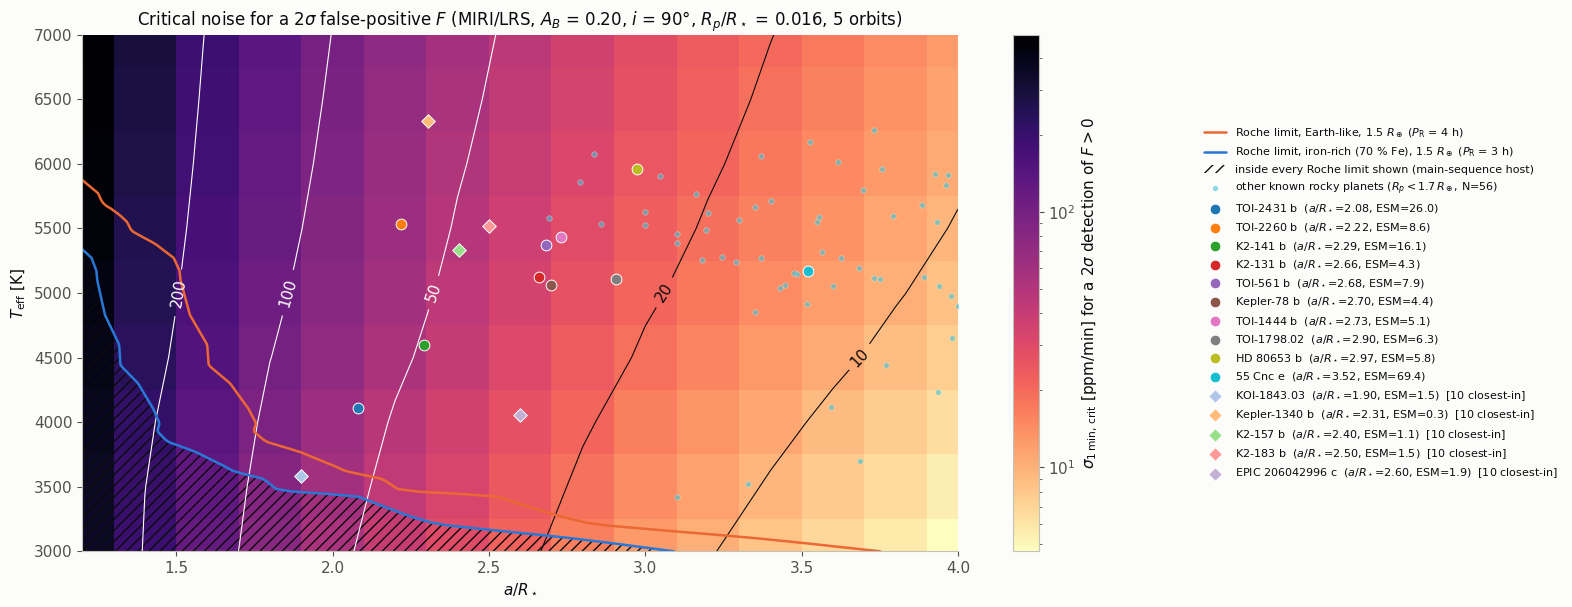

In [19]:
# Likelihood-ratio statistic of the spurious F per map cell: dchi2_F = chi2(A_B-only fit) - chi2(joint fit). No refit: fits= takes the chi^2 maps of 1.1 and 2.1 (same result as refitting).
z_false = 2.   # the false positive's significance [sigma] that the critical noise refers to
dchi2_map_FT, F_map_FT = false_F_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", fits=(chi2_map_T, chi2_map_JT, F_map_JT), **kw)
sig_crit_FT = plot_false_F_map(a_rs_grid, T_eff_grid, dchi2_map_FT, cfg, AGG, "st_teff", r"$T_{\rm eff}$ [K]", rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, z=z_false, planets=PAPER_PLANETS,
                               title=rf"Critical noise for a {z_false:g}$\sigma$ false-positive $F$ ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g}, {n_orbits} orbits)")
plt.show()

### 2.6 Per-planet and per-instrument false positives: the spurious $F$ at each planet's own geometry and noise
The map of 2.5 holds $R_p/R_\star$ and $i$ fixed. Here the two fits are compared for the planets of 1.2 and 2.2 at their **own** geometry and PandExo noise (first cell), and for `retrieval_planet` on the instruments of 1.3 and 2.3, including the joint NRS1 + NRS2 fit (second cell). No refit: both cells reuse those tables (`fits=`), so run them first. Per row: the expected significance $z_F = \sqrt{\Delta\chi^2_F}$ of the spurious $F$ with the notebook's `n_orbits`, the verdict against the threshold `z_false`, and three readings of the same number: the **noise margin** $z_F / z$ (the factor by which the noise may be worse, or must be better, for a $z\sigma$ false positive; this is the one that also applies to the joint fit, where all detectors scale alike), the critical noise $\sigma_{1\,\rm min,\,crit}$ (per detector for a joint fit, `sigma_1min_crit:<label>`), and the critical observing time $t_{\rm crit} = t_{\rm obs}\,(z/z_F)^2$. The implied nightside temperature is what the false positive would be reported as: $T_{\rm night}$ of the fitted $(A_B, F)$ from Kreidberg & Loeb eq. 1, for a planet whose true nightside is at the temperature floor.

What to look for: which planets and instruments cross the threshold already at `n_orbits`, and how far the others are from it ($t_{\rm crit}$ in hours of JWST time). Compare the planets' own critical noise with the map value at their position in 2.5: the difference is the $(R_p/R_\star)^2$ scaling and the inclination. Among the instruments, the joint NRS1 + NRS2 fit should be the strongest false positive, since it combines the two arrays' constraints on the same spurious $F$.

This is a hypothesis test: "The spurious F is a 1.5σ effect" therefore means: a fit of this model to data of this quality would reject F = 0 at the p-value that corresponds to 1.5 Gaussian σ, although the planet has no nightside redistribution.

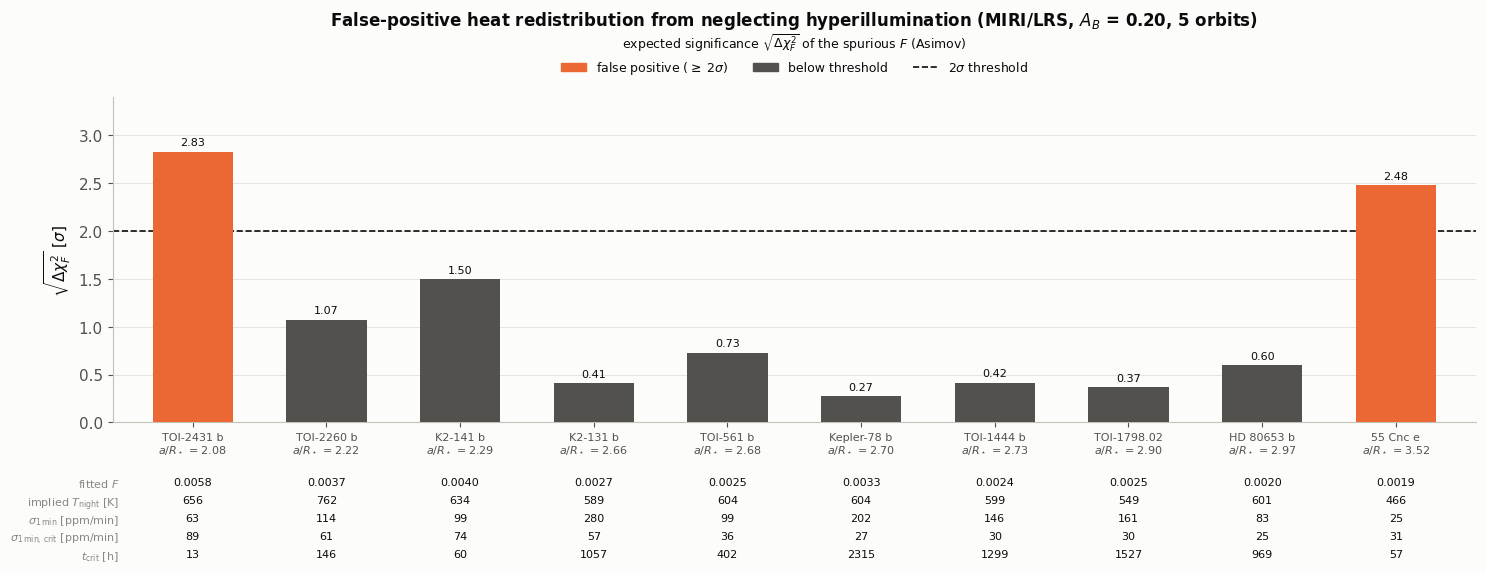

2 of 10 false positive: TOI-2431 b, 55 Cnc e
8 of 10 below threshold: TOI-2260 b, K2-141 b, K2-131 b, TOI-561 b, Kepler-78 b, TOI-1444 b, TOI-1798.02, HD 80653 b
       name  a_rs   esm  A_B_fit_naive  A_B_fit    F_fit  T_night_fit  dchi2_F    z_F  sigma_1min  sigma_1min_crit  noise_margin  t_obs  t_crit         verdict
 TOI-2431 b  2.08 25.96         0.1402  0.03086 0.005813        656.4    8.013  2.831       62.93            89.06         1.415   26.9   13.43  false positive
 TOI-2260 b  2.22 8.632         0.1718  0.04005 0.003684        761.7    1.155  1.075       114.2             61.4        0.5374   42.3   146.4 below threshold
   K2-141 b 2.292 16.12         0.1363  0.04388 0.003967        633.9     2.24  1.497       99.24            74.26        0.7483  33.64   60.07 below threshold
   K2-131 b  2.66 4.323         0.1582  0.09085 0.002726          589   0.1677 0.4096       280.3            57.41        0.2048  44.32    1057 below threshold
  TOI-561 b 2.683 7.927         0.1572

In [20]:
# The planets of 2.2 at their own geometry and PandExo noise (sigma_paper): both fits, dchi2_F and the decision columns. No refit: fits= reuses the tables of 1.2 and 2.2 (same result as refitting).
tab_FP = planet_false_F_table(cfg, A_B_true, PAPER_PLANETS, sigma_paper, z=z_false, AGG=AGG, fits=(tab_AB, tab_redist), **kw)
fig, ax = plot_planet_false_F_bars(tab_FP, planets=PAPER_PLANETS, title=f"False-positive heat redistribution from neglecting hyperillumination ({instrument}, $A_B$ = {A_B_true:.2f}, {n_orbits} orbits)")   # for a joint fit the noise rows are per detector
plt.show()
for v in (FALSE_POSITIVE, NO_FALSE_POSITIVE):
    sel = tab_FP[tab_FP.verdict == v]
    print(f"{len(sel)} of {len(tab_FP)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_FP[["name", "a_rs", "esm", "A_B_fit_naive", "A_B_fit", "F_fit", "T_night_fit", "dchi2_F", "z_F", *noise_cols(tab_FP), "noise_margin", "t_obs", "t_crit", "verdict"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4g}"))


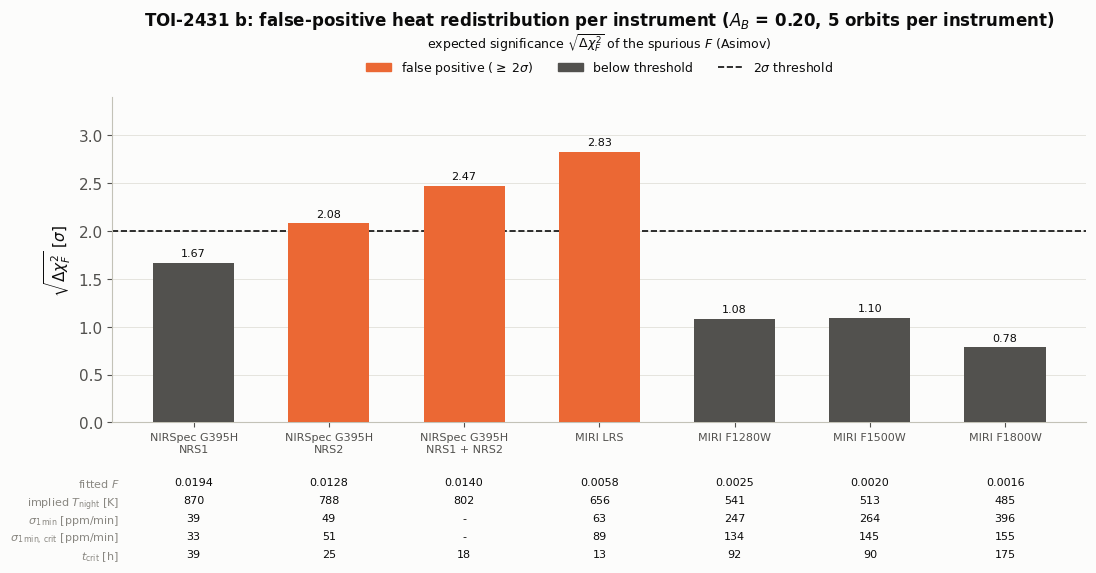

                                     instrument  A_B_fit_naive  A_B_fit    F_fit  T_night_fit  dchi2_F    z_F  sigma_1min  sigma_1min_crit  noise_margin  t_crit         verdict
                        JWST_NIRSpec.G395H_NRS1         0.1613   0.1068  0.01943        869.6    2.781  1.668       39.13            32.63        0.8339   38.69 below threshold
                        JWST_NIRSpec.G395H_NRS2         0.1522  0.08325  0.01279        788.3    4.341  2.083       49.41            51.47         1.042   24.79  false positive
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2         0.1575   0.1057  0.01402        801.7    6.118  2.474           -                -         1.237   17.59  false positive
                                       MIRI/LRS         0.1402  0.03086 0.005813        656.4    8.013  2.831       62.93            89.06         1.415   13.43  false positive
                                    MIRI/F1280W          0.133 -0.03383 0.002514        540.9    1.172  1.082      

In [21]:
# retrieval_planet on the instruments of 1.3 (same noise levels, sigma_inst), including the joint NRS1 + NRS2 fit. No refit: fits= reuses the tables of 1.3 and 2.3 (same result as refitting).
tab_FP_inst = instrument_false_F(cfg, retrieval_planet, retrieval_instruments, A_B_inj, z=z_false, sigma_1min=sigma_inst, fits=(tab_inst_AB, tab_inst_J), **kw)
fig, ax = plot_false_F_bars(tab_FP_inst, title=f"{retrieval_planet.name}: false-positive heat redistribution per instrument ($A_B$ = {A_B_inj:.2f}, {n_orbits} orbits per instrument)")
plt.show()
print(tab_FP_inst[["instrument", "A_B_fit_naive", "A_B_fit", "F_fit", "T_night_fit", "dchi2_F", "z_F", "sigma_1min", "sigma_1min_crit", "noise_margin", "t_crit", "verdict"]]
      .to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))


### 2.7 All three detectors in one fit: the multi-band consistency of $F$
The joint fits of 2.3 return a different spurious $F$ in every band: the fit trades albedo for a nightside, and how much nightside flux a given $F$ produces depends on the wavelength. A real atmosphere would have one $F$. Fitting NRS1, NRS2 and MIRI/LRS together with **one** $A_B$ and **one** $F$ (a baseline per detector) therefore cannot reach the $\chi^2$ of the separate fits. The cell prints, for the planets of 1.5, the joint fits of the parts and of the combined set, with $z_F = \sqrt{\Delta\chi^2_F}$ against the $A_B$-only fits of 1.5, and the `excess` of the combined $\chi^2_{\min}$ over the sum of the parts.

What to look for: the spread of the fitted $F$ between MIRI/LRS and NIRSpec, where the combined fit puts its single $F$, and the size of the excess. An excess of several units of $\chi^2$ is a measurable inconsistency: the spurious redistribution cannot be the same in all bands, which is a diagnostic that distinguishes it from real heat transport. Compare with the excess of the $A_B$-only fit in 1.5, which has no such band dependence. Run 1.5 first (it supplies the planets, the modes and the noise levels).

In [22]:
tab_multi_J = {nm: instrument_retrievals(cfg, hi_planets_by_name(nm), multi_instruments, A_B_true, redist=True, sigma_1min=tab_multi_AB[nm].attrs["sigma_1min"], **kw) for nm in multi_planets}
for nm, t in tab_multi_J.items():
    t = t.assign(mode=t["instrument"].map(MULTI_LABEL), z_F=np.sqrt(np.clip(tab_multi_AB[nm]["chi2"].to_numpy() - t["chi2"].to_numpy(), 0., None)), half_chi2=0.5 * t["chi2"])
    print(nm)
    print(t[["mode", "A_B_fit", "bias_A_B", "sigma_A_B", "bias_sigma", "F_fit", "z_F", "chi2", "half_chi2", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    c = t.set_index("mode")["chi2"]
    print(f"   chi2_min of the fit with redistribution: combined {c['NIRSpec + LRS']:.2f}, sum of the parts {c['MIRI/LRS'] + c['joint NIRSpec']:.2f}  ->  excess {c['NIRSpec + LRS'] - c['MIRI/LRS'] - c['joint NIRSpec']:.2f}"
          f"  (one F for all bands; chi2 / 2 is the likelihood part of ln B against the extended source, without the Occam term of the F prior)\n")

TOI-2431 b
         mode  A_B_fit  bias_A_B  sigma_A_B  bias_sigma    F_fit   z_F  chi2  half_chi2          verdict
     MIRI/LRS  0.03086   -0.1691    0.07049       2.399 0.005813 2.831 4.623      2.311 needs hyperillum
joint NIRSpec   0.1057   -0.0943    0.03461       2.724  0.01402 2.474 5.466      2.733 needs hyperillum
NIRSpec + LRS   0.1155  -0.08448      0.028       3.017 0.006571 2.993 15.35      7.674 needs hyperillum
   chi2_min of the fit with redistribution: combined 15.35, sum of the parts 10.09  ->  excess 5.26  (one F for all bands; chi2 / 2 is the likelihood part of ln B against the extended source, without the Occam term of the F prior)

K2-141 b
         mode  A_B_fit  bias_A_B  sigma_A_B  bias_sigma    F_fit   z_F  chi2  half_chi2          verdict
     MIRI/LRS  0.04388   -0.1561     0.1119       1.396 0.003967 1.497 1.874     0.9371 needs hyperillum
joint NIRSpec   0.1156  -0.08443    0.04763       1.773  0.01007 1.495 2.922      1.461 needs hyperillum
NIRSpec + LRS